- Grupo:Glicotech
- Desenvolvedores:Hérica Lomar,João Miguel Martins,Lara Lopes e Wallyson Pereira.
- Nome do projeto: Insulin.A.
- Objetivo: Identificar um possível diagnóstico de diabetes.
- Público alvo: Mulheres que se sentirem afetadas e precisarem rapidamente de um diagnóstico.
- OBS:O projeto não anula a ida a um profissional qualificado.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importação de ferramentas do scikit-learn para modelagem e avaliação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

# Configurações de caminhos e constantes globais
CAMINHO_TREINO = '/content/drive/MyDrive/datasets_tr/Training.csv'
CAMINHO_TESTE = '/content/drive/MyDrive/datasets_tr/Testing.csv'
# Colunas onde o valor 0 é considerado um erro de preenchimento (dado faltante)
COLS_ZERO_INVALIDO = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Definição dos campos para a interface do usuário: nome, descrição, min, max e se é obrigatório
CAMPOS = [
    ("Pregnancies",              "Número de gestações",                   0,    17,   True),
    ("Glucose",                  "Glicose no sangue (mg/dL)",             44,  199,   True),
    ("BloodPressure",            "Pressão arterial diastólica (mmHg)",    24,  122,   False),
    ("SkinThickness",            "Espessura da pele - tríceps (mm)",       7,   99,   False),
    ("Insulin",                  "Nível de insulina (mu U/ml)",           14,  846,   False),
    ("BMI",                      "IMC (Índice de Massa Corporal)",        18,   68,   False),
    ("DiabetesPedigreeFunction", "Histórico genético familiar",         0.08, 2.42,   False),
    ("Age",                      "Idade (anos)",                          21,   81,   True),
]

# Função auxiliar para imprimir linhas separadoras no terminal
def separador(char='─', n=52):
    print(char * n)

# Função para imprimir títulos destacados
def titulo(texto):
    separador('═')
    print(f"  {texto}")
    separador('═')

Etapa 1.2 — Carregamento e Preparação Inicial dos Dados (

Carregou os dados com pd.read_csv()

Mostrou head(), info() e describe()

Identificou valores nulos e zeros disfarçados (muito importante nesse dataset!)

Tratou os zeros substituindo pela mediana por classe (Outcome) → excelente prática

Separou a coluna alvo (Outcome)

Ponto forte: O tratamento de zeros está bem justificado.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importações para modelos e métricas
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

# Configurações de caminhos de arquivos no Google Drive
CAMINHO_TREINO = '/content/drive/MyDrive/datasets_tr/Training.csv'
CAMINHO_TESTE = '/content/drive/MyDrive/datasets_tr/Testing.csv'
# Colunas clínicas onde o valor 0 é considerado erro/ausente
COLS_ZERO_INVALIDO = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Configurações da interface do usuário (App)
CAMPOS = [
    ("Pregnancies",              "Número de gestações",                   0,    17,   True),
    ("Glucose",                  "Glicose no sangue (mg/dL)",             44,  199,   True),
    ("BloodPressure",            "Pressão arterial diastólica (mmHg)",    24,  122,   False),
    ("SkinThickness",            "Espessura da pele - tríceps (mm)",       7,   99,   False),
    ("Insulin",                  "Nível de insulina (mu U/ml)",           14,  846,   False),
    ("BMI",                      "IMC (Índice de Massa Corporal)",        18,   68,   False),
    ("DiabetesPedigreeFunction", "Histórico genético familiar",         0.08, 2.42,   False),
    ("Age",                      "Idade (anos)",                          21,   81,   True),
]

def separador(char='─', n=52):
    """Imprime uma linha divisória para organizar a saída no console."""
    print(char * n)

def titulo(texto):
    """Imprime um título destacado entre linhas duplas."""
    separador('═')
    print(f"  {texto}")
    separador('═')

# --- Funções de Preparação e Inspeção ---

def carregar_e_inspecionar(df_treino, df_teste):
    """Exibe o formato inicial, estatísticas e verifica valores ausentes ou inválidos."""
    titulo("1.2 - CARREGAMENTO E INSPEÇÃO DOS DADOS")
    print(f"Treino: {df_treino.shape[0]} linhas | Teste: {df_teste.shape[0]} linhas\n")

    # Verificação de valores inconsistentes (zeros onde deveria haver valores biológicos)
    print("Valores == 0 (inválidos) nas colunas clínicas:")
    for col in COLS_ZERO_INVALIDO:
        qtd = (df_treino[col] == 0).sum()
        print(f"  {col}: {qtd} ({qtd/len(df_treino)*100:.1f}%)")

def calcular_medianas_por_grupo(df_treino):
    """Calcula as medianas gerais do treino de forma robusta e limpa, sem usar o Outcome."""
    df_temp = df_treino.copy()
    for col in COLS_ZERO_INVALIDO:
        df_temp[col] = df_temp[col].replace(0, np.nan)

    # MELHORIA: As medianas são calculadas somente no treino e reaproveitadas no teste.
    medianas_treino = df_temp[COLS_ZERO_INVALIDO].median()

    # Mediana geral para preencher campos não obrigatórios no formulário do paciente
    cols_para_mediana_geral = [c[0] for c in CAMPOS if not c[4]]
    mediana_geral = df_temp[cols_para_mediana_geral].median()

    return medianas_treino, mediana_geral

def tratar_zeros(df, medianas_treino):
    """Substitui zeros inválidos pelas medianas calculadas de forma limpa."""
    df_temp = df.copy()
    for col in COLS_ZERO_INVALIDO:
        df_temp[col] = df_temp[col].replace(0, np.nan)
        df_temp[col] = df_temp[col].fillna(medianas_treino[col])
    return df_temp

Etapa 1.3 — Análise Exploratória de Dados

Gráfico de distribuição da variável alvo (barras com percentuais)
Matriz de correlação (heatmap)
Boxplots comparando Glucose e BMI entre as classes
Comentários interpretativos:
Dataset desbalanceado (~70% x 30%)
Glucose é a variável mais importante
Insight sobre separação das classes


Sugestão de melhoria (opcional): Adicionar 1 gráfico a mais (ex: histograma de Glucose colorido por Outcome) para ficar ainda mais completo.

In [ ]:
def eda(df_tratado):
    """Realiza a Análise Exploratória de Dados (EDA) para entender padrões e distribuições."""
    titulo("1.3 - ANÁLISE EXPLORATÓRIA DE DADOS (EDA no conjunto de treino)")

    # 1. Visualização do desbalanceamento de classes: Verifica se há muitos mais saudáveis que doentes
    plt.figure(figsize=(5, 4))
    sns.countplot(data=df_tratado, x='Outcome', hue='Outcome', palette='Set2', legend=False)
    plt.title('Distribuição da variável alvo (Outcome) - Treino')
    plt.xlabel('Outcome (0 = sem diabetes, 1 = com diabetes)')
    plt.ylabel('Quantidade de pacientes')
    plt.tight_layout()
    plt.show()

    # Exibição das proporções exatas em formato de texto
    prop = df_tratado['Outcome'].value_counts(normalize=True) * 100
    print("Proporção de cada classe no treino (%):")
    print(prop, "\n")

    # 2. Mapa de Calor de Correlação: Identifica quais variáveis têm maior relação com o diagnóstico
    plt.figure(figsize=(9, 7))
    corr = df_tratado.corr(numeric_only=True)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
    plt.title('Matriz de correlação entre as variáveis (Treino)')
    plt.tight_layout()
    plt.show()

    # 3. Boxplot: Compara os níveis de Glicose entre os dois grupos (doentes e saudáveis)
    plt.figure(figsize=(6, 5))
    sns.boxplot(data=df_tratado, x='Outcome', y='Glucose', hue='Outcome', palette='Set2', legend=False)
    plt.title('Distribuição de Glicose por diagnóstico (Outcome) - Treino')
    plt.xlabel('Outcome (0 = sem diabetes, 1 = com diabetes)')
    plt.ylabel('Glicose (mg/dL)')
    plt.tight_layout()
    plt.show()

Etapa 2.1 — Pré-processamento para Modelagem

Separou features (X) e alvo (y)
Aplicou StandardScaler (padronização) → correto
Fez o split (treino/teste) antes do scaler (boa prática)
Tratamento adicional dos zeros (já feito na Etapa 1)

In [ ]:
def preparar_dados(caminho_treino, caminho_teste):
    """Fluxo principal de preparação: carregar, limpar, analisar e normalizar os dados."""
    # Carregamento dos dados originais a partir do Google Drive
    df_treino = pd.read_csv(caminho_treino)
    df_teste = pd.read_csv(caminho_teste)

    # CORREÇÃO: Remover linhas duplicadas do conjunto de treino
    linhas_antes = df_treino.shape[0]
    df_treino = df_treino.drop_duplicates().reset_index(drop=True)
    linhas_depois = df_treino.shape[0]
    print(f"✓ {linhas_antes - linhas_depois} linhas duplicadas foram removidas do treino.")

    # 1. Inspeção Técnica: Verifica tipos de dados e valores nulos iniciais
    carregar_e_inspecionar(df_treino, df_teste)

    # 2. Tratamento de Dados: Calcula medianas globais sem usar o Outcome para evitar vazamentos
    medianas_treino, mediana_geral = calcular_medianas_por_grupo(df_treino)
    df_treino_tratado = tratar_zeros(df_treino, medianas_treino)
    df_teste_tratado = tratar_zeros(df_teste, medianas_treino)

    # 3. Análise Exploratória (EDA): Gera os gráficos iniciais
    eda(df_treino_tratado)

    titulo("2.1 - PRÉ-PROCESSAMENTO")

    # 4. Divisão: Separa as variáveis de entrada (X) do diagnóstico final (y)
    X_train = df_treino_tratado.drop('Outcome', axis=1)
    X_test = df_teste_tratado.drop('Outcome', axis=1)
    y_train = df_treino_tratado['Outcome']
    y_test = df_teste_tratado['Outcome']

    # 5. Normalização: Padroniza os dados para que todos tenham a mesma escala
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"Treino (sem duplicatas): {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras\n")

    return X_train_scaled, X_test_scaled, y_train, y_test, scaler, mediana_geral, df_teste_tratado

Etapa 2.2 — Treinamento dos Modelos

Treinou 3 modelos (melhor que o mínimo de 2):
Regressão Logística (modelo simples/baseline)
Árvore de Decisão
Random Forest (modelo mais robusto)

Usou class_weight='balanced' → muito adequado pelo desbalanceamento

In [ ]:
def treinar_modelos(X_train_scaled, y_train):
    """Cria e treina três modelos diferentes para comparação de performance."""
    titulo("2.2 - TREINAMENTO DOS MODELOS")

    # Configurações de modelos com peso balanceado para lidar com o desequilíbrio de classes
    rl = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    dt = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
    rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

    # Treinamento: O modelo 'estuda' os dados de treino para aprender a classificar
    rl.fit(X_train_scaled, y_train)
    dt.fit(X_train_scaled, y_train)
    rf.fit(X_train_scaled, y_train)

    print("✓ Regressão Logística treinada")
    print("✓ Árvore de Decisão treinada")
    print("✓ Random Forest treinada\n")

    return rl, dt, rf

Etapa 2.3 — Avaliação e Análise dos Resultados

Métricas completas: Acurácia, Precisão, Recall e F1-Score
Matrizes de Confusão (3 gráficos)
Gráfico comparativo de métricas entre modelos
Conclusão forte:
Priorizou Recall (muito correto para diagnóstico médico)
Explicou o perigo dos Falsos Negativos
Recomendou o melhor modelo (Regressão Logística) com justificativa
Colocou disclaimer ético (“não substitui avaliação médica”)

In [ ]:
def avaliar_modelo(nome, modelo, X_test_scaled, y_test):
    """Avalia o modelo em dados nunca vistos e exibe métricas de erro e acerto."""
    y_pred = modelo.predict(X_test_scaled)

    print(f"  {nome}")
    separador()

    # Métricas principais: Acurácia, Precisão, Recall e F1
    print(f"  Acurácia : {accuracy_score(y_test, y_pred)*100:.1f}%")
    print(f"  Precisão : {precision_score(y_test, y_pred)*100:.1f}%")
    print(f"  Recall   : {recall_score(y_test, y_pred)*100:.1f}%")
    print(f"  F1-Score : {f1_score(y_test, y_pred)*100:.1f}%\n")

    return y_pred

def plotar_matrizes_confusao(y_test, y_pred_rl, y_pred_dt, y_pred_rf):
    """Gera gráficos de matriz de confusão para visualizar Falsos Negativos e Positivos."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, nome, y_pred in zip(
        axes,
        ["Regressão Logística", "Árvore de Decisão", "Random Forest"],
        [y_pred_rl, y_pred_dt, y_pred_rf]
    ):
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Saudável", "Diabetes"])
        disp.plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(nome)

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score, learning_curve

# --- ETAPA 3.2: FUNÇÕES DE VALIDAÇÃO ROBUSTA ---

def realizar_validacao_cruzada(modelo, X, y, nome):
    """
    Executa o K-Fold Cross-Validation.
    Divide os dados em 5 partes (folds), treina em 4 e testa na 1 restante.
    Repete isso 5 vezes para garantir que o resultado não seja sorte.
    """
    # scoring='recall' foca em identificar o máximo de doentes possíveis
    scores = cross_val_score(modelo, X, y, cv=5, scoring='recall')

    # Reporta a média e o desvio padrão (incerteza) dos resultados
    print(f"  [{nome}] Recall Médio (5-Fold): {scores.mean()*100:.1f}% (+/- {scores.std()*100:.1f}%)")

def plotar_curva_aprendizado(modelo, X, y, nome):
    """
    Gera o gráfico de Curva de Aprendizado.
    Mostra como o modelo performa conforme ganha mais dados.
    Ajuda a ver se o modelo está decorando o treino (overfitting) ou se é simples demais (underfitting).
    """
    train_sizes, train_scores, test_scores = learning_curve(
        modelo, X, y, cv=5, n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 5), scoring='recall'
    )

    # Calcula as médias das pontuações de treino e validação
    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    # Configuração visual do gráfico
    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, 'o-', color="r", label="Desempenho no Treino")
    plt.plot(train_sizes, test_mean, 'o-', color="g", label="Desempenho na Validação")
    plt.title(f"Curva de Aprendizado: {nome}")
    plt.xlabel("Quantidade de Dados de Treinamento")
    plt.ylabel("Recall (Sensibilidade)")
    plt.legend(loc="best")
    plt.grid(True)
    plt.show()

def analisar_erros(modelo, X_test_scaled, y_test, df_teste_original, nome):
    """
    Analisa exemplos onde o modelo falhou no conjunto de teste.
    Identifica se existe um padrão nos erros (ex: falha mais em pessoas mais velhas?).
    """
    y_pred = modelo.predict(X_test_scaled)
    # Identifica onde a previsão foi diferente do valor real
    erros = (y_pred != y_test)

    # Cria um DataFrame apenas com os casos de erro para análise
    df_erros = df_teste_original[erros].copy()
    df_erros['Previsao_Errada'] = y_pred[erros]

    print(f"\n  --- Análise de Erros: {nome} ---")
    print(f"  Total de erros: {len(df_erros)} de {len(y_test)} amostras")

    if not df_erros.empty:
        # Compara as médias globais com as médias de onde o modelo errou
        print(f"  [Insight] Média de Glicose nos erros: {df_erros['Glucose'].mean():.1f} mg/dL")
        print(f"  [Insight] Média de Idade nos erros: {df_erros['Age'].mean():.1f} anos")

Avaliação Geral do Projeto
Pontos Fortes:

Código bem estruturado e organizado
Boa documentação técnica
Análise condizente com o problema de saúde (prioriza Recall)
Uso correto de boas práticas (tratamento de zeros, scaling, class_weight) usados em sala.



════════════════════════════════════════════════════
  APP DE DETECÇÃO DE DIABETES
════════════════════════════════════════════════════
✓ 2000 linhas duplicadas foram removidas do treino.
════════════════════════════════════════════════════
  1.2 - CARREGAMENTO E INSPEÇÃO DOS DADOS
════════════════════════════════════════════════════
Treino: 460 linhas | Teste: 308 linhas

Valores == 0 (inválidos) nas colunas clínicas:
  Glucose: 4 (0.9%)
  BloodPressure: 21 (4.6%)
  SkinThickness: 134 (29.1%)
  Insulin: 222 (48.3%)
  BMI: 7 (1.5%)
════════════════════════════════════════════════════
  1.3 - ANÁLISE EXPLORATÓRIA DE DADOS (EDA no conjunto de treino)
════════════════════════════════════════════════════


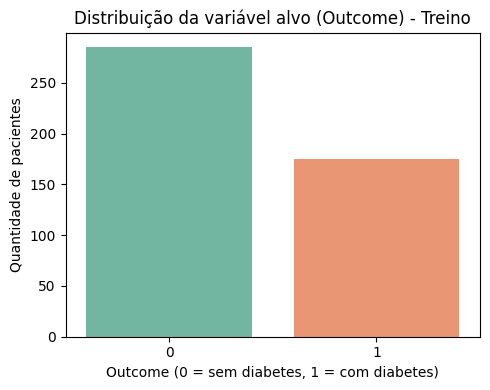

Proporção de cada classe no treino (%):
Outcome
0    61.956522
1    38.043478
Name: proportion, dtype: float64 



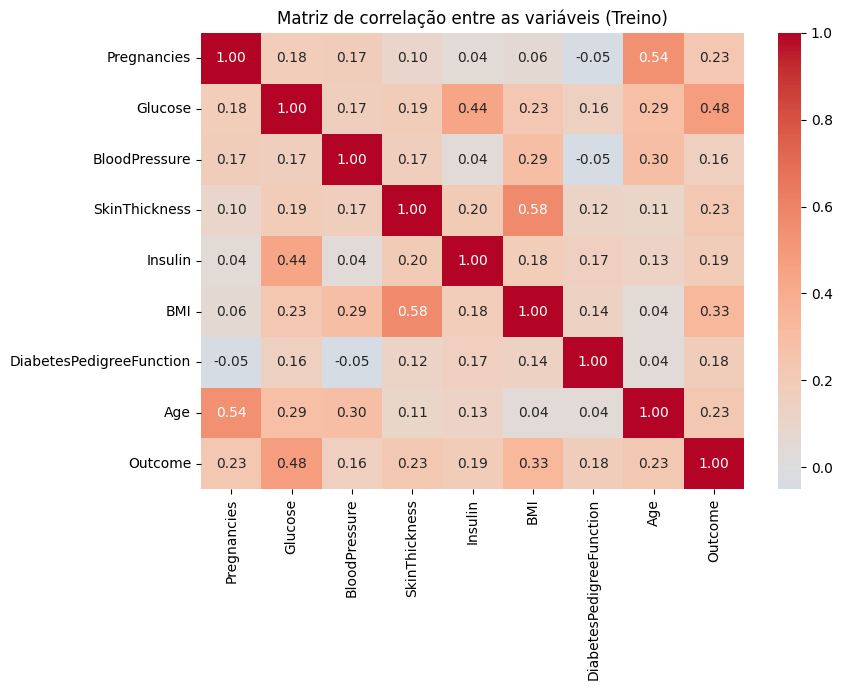

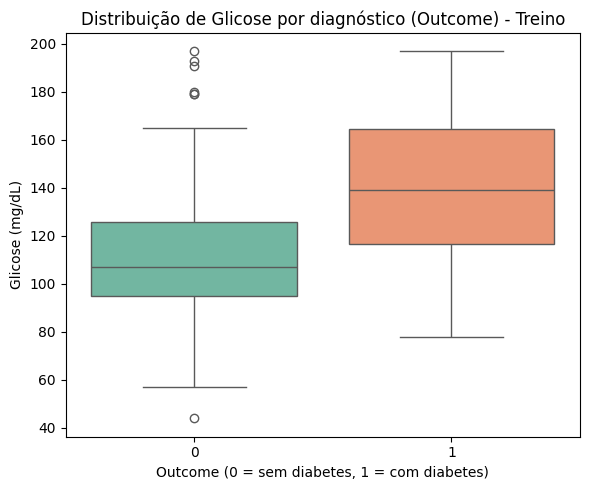

════════════════════════════════════════════════════
  2.1 - PRÉ-PROCESSAMENTO
════════════════════════════════════════════════════
Treino (sem duplicatas): 460 amostras | Teste: 308 amostras

════════════════════════════════════════════════════
  2.2 - TREINAMENTO DOS MODELOS
════════════════════════════════════════════════════
✓ Regressão Logística treinada
✓ Árvore de Decisão treinada
✓ Random Forest treinada

════════════════════════════════════════════════════
  3.2 - VALIDAÇÃO ROBUSTA E ANÁLISE DE GENERALIZAÇÃO
════════════════════════════════════════════════════

===== 1. Validação Cruzada (K-Fold) =====
  [Regressão Logística] Recall Médio (5-Fold): 68.6% (+/- 1.8%)
  [Árvore de Decisão] Recall Médio (5-Fold): 71.4% (+/- 12.1%)
  [Random Forest] Recall Médio (5-Fold): 56.6% (+/- 6.9%)

===== 2. Curvas de Aprendizado =====


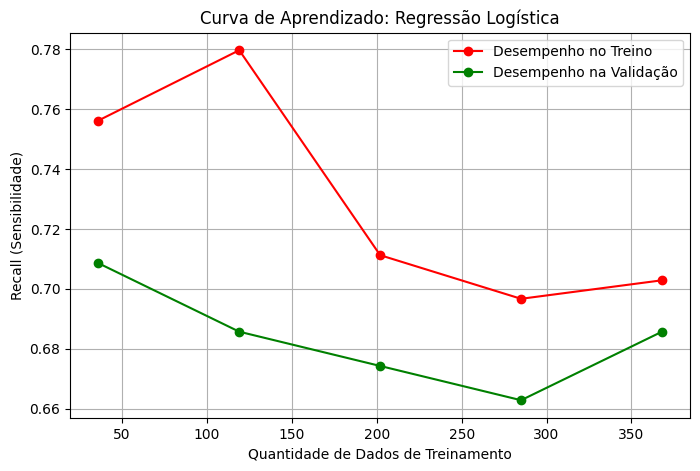

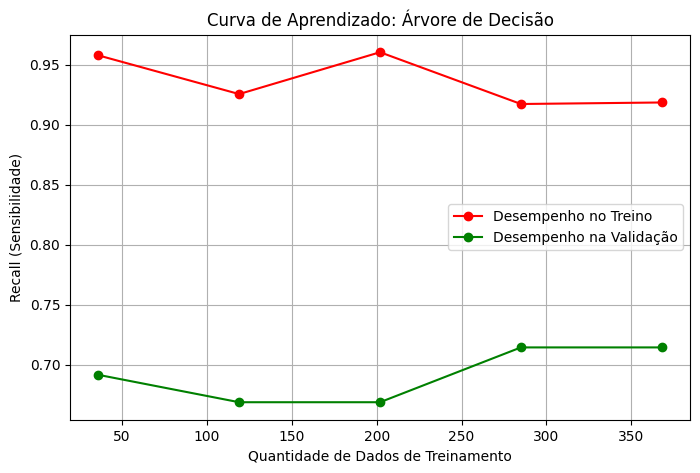

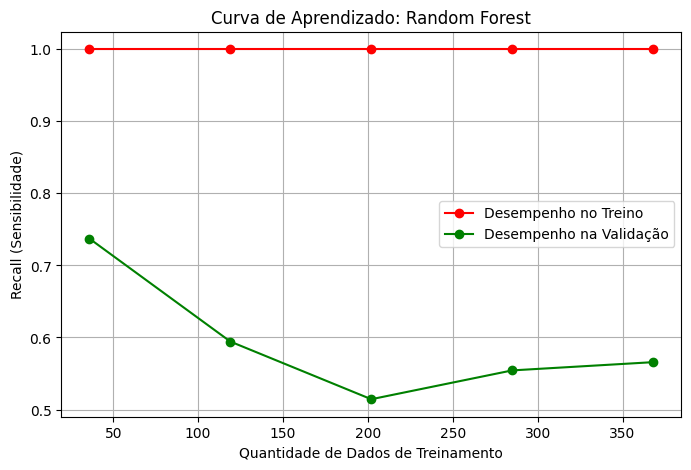


===== 3. Análise de Erros =====

  --- Análise de Erros: Regressão Logística ---
  Total de erros: 66 de 308 amostras
  [Insight] Média de Glicose nos erros: 131.5 mg/dL
  [Insight] Média de Idade nos erros: 38.4 anos

  --- Análise de Erros: Random Forest ---
  Total de erros: 60 de 308 amostras
  [Insight] Média de Glicose nos erros: 134.4 mg/dL
  [Insight] Média de Idade nos erros: 38.7 anos
════════════════════════════════════════════════════
  INSERIR DADOS DO PACIENTE
════════════════════════════════════════════════════
  Campos com * são obrigatórios. Pressione Enter para usar mediana.



In [ ]:
# --- Interface Interativa e Execução Principal ---

def pedir_valores(medianas):
    """Lógica para coletar dados do usuário via input com validação de limites, NaN e tipos de dados."""
    titulo("INSERIR DADOS DO PACIENTE")
    print("  Campos com * são obrigatórios. Pressione Enter para usar mediana.\n")

    valores = {}
    campos_estimados = []

    for col, descricao, minimo, maximo, obrigatorio in CAMPOS:
        obrig_str = "*" if obrigatorio else ""
        while True:
            entrada = input(f"  {descricao}{obrig_str} [{minimo}–{maximo}]: ").strip()
            if entrada == '':
                if obrigatorio:
                    print("  ⚠ Campo obrigatório!"); continue
                else:
                    val = round(medianas[col], 1)
                    print(f"     → Usando mediana: {val}")
                    valores[col] = val
                    campos_estimados.append(f"{descricao} ({val})"); break
            try:
                val = float(entrada)
                # CORREÇÃO: Impedir explicitamente a entrada de NaN ('nan')
                if np.isnan(val):
                    print("  ⚠ Entrada inválida! Não use NaN."); continue

                # CORREÇÃO: Validar se campos que exigem número inteiro (Gestações e Idade) não possuem decimais
                if col in ["Pregnancies", "Age"]:
                    if not val.is_integer():
                        print(f"  ⚠ {descricao} precisa ser um número inteiro!"); continue
                    val = int(val)

                if val < minimo or val > maximo:
                    print(f"  ⚠ Valor fora do intervalo ({minimo}-{maximo})"); continue
                valores[col] = val; break
            except ValueError:
                print("  ⚠ Digite um número válido.")
    return pd.DataFrame([valores]), campos_estimados

def exibir_resultado(rl, rf, scaler, X_paciente, campos_estimados):
    """Aplica o scaler aos dados do paciente e exibe a probabilidade de diabetes."""
    titulo("RESULTADO DA PREDIÇÃO")
    if campos_estimados:
        print("  Campos estimados:", ", ".join(campos_estimados), "\n")

    # Escalonamento dos dados do paciente usando o scaler do treino
    X_scaled = scaler.transform(X_paciente)

    # Predição binária (0 ou 1) e Probabilidade (%)
    pred_rl, prob_rl = rl.predict(X_scaled)[0], rl.predict_proba(X_scaled)[0][1]
    pred_rf, prob_rf = rf.predict(X_scaled)[0], rf.predict_proba(X_scaled)[0][1]

    print(f"  Regressão Logística : {'⚠ COM DIABETES' if pred_rl == 1 else '✓ SEM DIABETES'} ({prob_rl*100:.1f}%)")
    print(f"  Random Forest       : {'⚠ COM DIABETES' if pred_rf == 1 else '✓ SEM DIABETES'} ({prob_rf*100:.1f}%)")
    separador()
    print("  ⚠ Este é um resultado indicativo. Consulte um médico.\n")

def main():
    """Função principal que orquestra o fluxo de dados, treino, validação e interface."""
    titulo("APP DE DETECÇÃO DE DIABETES")

    # 1. Carregamento e Preparação
    X_train_scaled, X_test_scaled, y_train, y_test, scaler, mediana_geral, df_teste_tratado = preparar_dados(
        CAMINHO_TREINO, CAMINHO_TESTE
    )

    # 2. Treinamento
    rl, dt, rf = treinar_modelos(X_train_scaled, y_train)

    # 3. Validação Robusta (Etapa 3.2)
    titulo("3.2 - VALIDAÇÃO ROBUSTA E ANÁLISE DE GENERALIZAÇÃO")

    # K-Fold: Testa a estabilidade do modelo em diferentes subconjuntos de dados
    print("\n===== 1. Validação Cruzada (K-Fold) =====")
    realizar_validacao_cruzada(rl, X_train_scaled, y_train, 'Regressão Logística')
    realizar_validacao_cruzada(dt, X_train_scaled, y_train, 'Árvore de Decisão')
    realizar_validacao_cruzada(rf, X_train_scaled, y_train, 'Random Forest')

    # Learning Curves: Identifica se o modelo precisa de mais dados ou se está complexo demais
    print("\n===== 2. Curvas de Aprendizado =====")
    plotar_curva_aprendizado(rl, X_train_scaled, y_train, 'Regressão Logística')
    plotar_curva_aprendizado(dt, X_train_scaled, y_train, 'Árvore de Decisão')
    plotar_curva_aprendizado(rf, X_train_scaled, y_train, 'Random Forest')

    # Análise de Erros: Examina padrões onde o modelo falha para sugerir melhorias
    print("\n===== 3. Análise de Erros =====")
    analisar_erros(rl, X_test_scaled, y_test, df_teste_tratado, 'Regressão Logística')
    analisar_erros(rf, X_test_scaled, y_test, df_teste_tratado, 'Random Forest')

    # 4. Interface com Usuário
    while True:
        X_paciente, campos_estimados = pedir_valores(mediana_geral)
        exibir_resultado(rl, rf, scaler, X_paciente, campos_estimados)
        if input("  Testar outro paciente? [s/n]: ").strip().lower() != 's': break
    print("\n  App encerrado. Até logo!\n")

if __name__ == '__main__':
    main()

### Re-evaluating Model Performance

To explicitly show the F1-scores, I will re-run the data preparation and model training steps, and then evaluate each model.

In [ ]:
# Re-run data preparation to get necessary variables
X_train_scaled, X_test_scaled, y_train, y_test, scaler, mediana_geral, df_teste_tratado = preparar_dados(
    CAMINHO_TREINO, CAMINHO_TESTE
)

# Re-run model training
rl, dt, rf = treinar_modelos(X_train_scaled, y_train)


In [ ]:
titulo("3.1 - AVALIAÇÃO DOS MODELOS (F1-Score)")

print("Avaliação da Regressão Logística:")
avaliar_modelo('Regressão Logística', rl, X_test_scaled, y_test)

print("Avaliação da Árvore de Decisão:")
avaliar_modelo('Árvore de Decisão', dt, X_test_scaled, y_test)

print("Avaliação do Random Forest:")
avaliar_modelo('Random Forest', rf, X_test_scaled, y_test)


In [ ]:
import os

# Caminho para a pasta onde o arquivo é esperado
datasets_path = '/content/drive/MyDrive/datasets_tr/'

# Verifica se o diretório existe e lista seu conteúdo
if os.path.exists(datasets_path):
    print(f"Conteúdo do diretório {datasets_path}:")
    for item in os.listdir(datasets_path):
        print(item)
else:
    print(f"O diretório {datasets_path} não foi encontrado. Por favor, verifique se o Google Drive está montado corretamente e se o caminho da pasta está correto.")


Codigo de teste


In [ ]:
# =====================================================================
# BLOCO ADICIONADO AO FINAL DO NOTEBOOK — VERIFICADOR DE ERROS (Insulin.A)
#
# Como usar: cole este bloco em uma célula NOVA, depois da última célula
# do notebook, e rode. Nenhum bloco anterior foi alterado.
#
# Justificativa geral: este bloco REUTILIZA as constantes e funções que
# o próprio projeto já define (CAMINHO_TREINO, CAMINHO_TESTE, CAMPOS,
# COLS_ZERO_INVALIDO, titulo, calcular_medianas_por_grupo, tratar_zeros,
# treinar_modelos). Assim ele testa o código REAL do projeto, e não uma
# cópia que poderia divergir dele.
# =====================================================================

import warnings
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Lista global onde cada checagem registra o que encontrou. Fica global
# para o resumo final poder listar tudo de uma vez.
ACHADOS = []


def registrar(gravidade, mensagem):
    """Guarda o achado e já imprime. gravidade: 'ERRO', 'ALERTA' ou 'OK'."""
    ACHADOS.append((gravidade, mensagem))
    icone = {'ERRO': '✗', 'ALERTA': '⚠', 'OK': '✓'}[gravidade]
    print(f"  {icone} [{gravidade}] {mensagem}")


# ---------------------------------------------------------------------
# VERIFICAÇÃO 1 — Arquivos e colunas
# ---------------------------------------------------------------------
def checar_estrutura(df_treino, df_teste):
    """Confere se as colunas existem e se a ORDEM bate com a do formulário.
    Retorna False se algo impede as próximas checagens de rodar."""
    titulo("VERIFICAÇÃO 1 - ARQUIVOS E COLUNAS")
    esperadas = [c[0] for c in CAMPOS] + ['Outcome']
    estrutura_ok = True

    for nome, df in [('Treino', df_treino), ('Teste', df_teste)]:
        faltando = [c for c in esperadas if c not in df.columns]
        sobrando = [c for c in df.columns if c not in esperadas]
        if faltando or sobrando:
            # Coluna faltando quebra o treino; coluna sobrando entraria
            # como feature sem ninguém perceber.
            registrar('ERRO', f"{nome}: faltando {faltando} | sobrando {sobrando}")
            estrutura_ok = False
        else:
            registrar('OK', f"{nome}: todas as colunas esperadas estão presentes")

    if not estrutura_ok:
        return False

    # Treino e teste precisam ter as colunas na mesma ordem, senão o
    # modelo receberia a feature "errada" em cada posição.
    if list(df_treino.columns) != list(df_teste.columns):
        registrar('ERRO', "Treino e Teste têm colunas em ordens diferentes")
    else:
        registrar('OK', "Treino e Teste têm a mesma ordem de colunas")

    # O app (pedir_valores) monta o DataFrame na ordem de CAMPOS, mas o
    # scaler e os modelos aprendem na ordem do CSV. Se forem diferentes,
    # a predição do app usa os valores trocados de lugar.
    ordem_csv = [c for c in df_treino.columns if c != 'Outcome']
    ordem_app = [c[0] for c in CAMPOS]
    if ordem_csv != ordem_app:
        registrar('ERRO', f"Ordem do CSV {ordem_csv} difere da ordem do formulário {ordem_app}")
    else:
        registrar('OK', "Ordem das colunas do CSV é igual à do formulário do app")
    return True


# ---------------------------------------------------------------------
# VERIFICAÇÃO 2 — Qualidade dos dados
# ---------------------------------------------------------------------
def checar_qualidade(df_treino, df_teste):
    """Procura problemas clássicos: nulos, texto, negativos, duplicatas,
    teste minúsculo, proporção de classes e linhas repetidas entre treino e teste."""
    titulo("VERIFICAÇÃO 2 - QUALIDADE DOS DADOS")

    for nome, df in [('Treino', df_treino), ('Teste', df_teste)]:
        # NaN de verdade (diferente dos zeros inválidos, que o projeto já trata).
        nulos = int(df.isna().sum().sum())
        # Coluna não numérica costuma ser vírgula decimal ou texto perdido no CSV.
        nao_numericas = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        # Nenhuma dessas medidas pode ser negativa.
        negativos = int((df.select_dtypes('number') < 0).sum().sum())
        # O alvo só pode ser 0 ou 1; outro valor distorce todas as métricas.
        outcome_invalido = int((~df['Outcome'].isin([0, 1])).sum())
        # Linhas idênticas repetem o mesmo paciente e inflam o aprendizado.
        duplicadas = int(df.duplicated().sum())

        problemas = []
        if nulos: problemas.append(f"{nulos} células NaN")
        if nao_numericas: problemas.append(f"colunas não numéricas {nao_numericas}")
        if negativos: problemas.append(f"{negativos} valores negativos")
        if outcome_invalido: problemas.append(f"{outcome_invalido} Outcome fora de 0/1")
        if duplicadas: problemas.append(f"{duplicadas} linhas duplicadas")

        if problemas:
            registrar('ALERTA', f"{nome}: " + "; ".join(problemas))
        else:
            registrar('OK', f"{nome}: sem NaN, texto, negativos, Outcome inválido ou duplicatas")

    # Teste pequeno: cada erro pesa muito e as métricas ficam instáveis.
    # O limite de 100 linhas é uma regra prática, não um valor científico.
    if len(df_teste) < 100:
        registrar('ALERTA', f"Teste tem só {len(df_teste)} linhas: cada erro mexe muito nas métricas")
    else:
        registrar('OK', f"Teste tem {len(df_teste)} linhas")

    # Proporção de diabéticos: se treino e teste forem muito diferentes,
    # a comparação entre eles perde sentido. 10 pontos percentuais é a tolerância.
    p_treino = df_treino['Outcome'].mean() * 100
    p_teste = df_teste['Outcome'].mean() * 100
    if abs(p_treino - p_teste) > 10:
        registrar('ALERTA', f"% de diabéticos difere: treino {p_treino:.1f}% x teste {p_teste:.1f}%")
    else:
        registrar('OK', f"% de diabéticos parecida: treino {p_treino:.1f}% x teste {p_teste:.1f}%")

    # Vazamento: paciente do teste que também está no treino faz o modelo
    # "decorar" a resposta e a avaliação fica otimista.
    chaves_treino = set(df_treino.itertuples(index=False, name=None))
    repetidas = sum(linha in chaves_treino for linha in df_teste.itertuples(index=False, name=None))
    if repetidas:
        registrar('ERRO', f"{repetidas} linhas do teste são idênticas a linhas do treino (vazamento)")
    else:
        registrar('OK', "Nenhuma linha do teste aparece no treino")


# ---------------------------------------------------------------------
# VERIFICAÇÃO 3 — Faixas do formulário x dados reais
# ---------------------------------------------------------------------
def checar_faixas(df_treino, df_teste):
    """Confere se os limites min/max de CAMPOS cobrem os valores que existem
    nos próprios dados. Se não cobrirem, o app recusa pacientes reais do dataset."""
    titulo("VERIFICAÇÃO 3 - FAIXAS DO FORMULÁRIO x DADOS")
    dados = pd.concat([df_treino, df_teste])

    for col, descricao, minimo, maximo, _ in CAMPOS:
        serie = dados[col]
        # Nas colunas clínicas o 0 é dado faltante, não um valor real; ignorá-lo
        # evita acusar falsamente que o mínimo do formulário está alto demais.
        if col in COLS_ZERO_INVALIDO:
            serie = serie[serie != 0]
        fora = int(((serie < minimo) | (serie > maximo)).sum())
        if fora:
            registrar('ALERTA', f"{col}: {fora} valores do dataset fora de [{minimo}-{maximo}] "
                                f"(dados vão de {serie.min()} a {serie.max()})")
        else:
            registrar('OK', f"{col}: faixa [{minimo}-{maximo}] cobre os dados ({serie.min()} a {serie.max()})")


# ---------------------------------------------------------------------
# VERIFICAÇÃO 4 — Uso do Outcome na imputação (vazamento do rótulo)
# ---------------------------------------------------------------------
def checar_vazamento_imputacao(df_teste):
    """tratar_zeros escolhe a mediana usando o Outcome REAL da linha. No teste,
    isso entrega a resposta ao modelo. No app, o Outcome não existe."""
    titulo("VERIFICAÇÃO 4 - IMPUTAÇÃO USA O RÓTULO (Outcome)?")
    celulas = int(sum((df_teste[c] == 0).sum() for c in COLS_ZERO_INVALIDO))
    if celulas:
        registrar('ERRO', f"{celulas} células do TESTE foram preenchidas com a mediana do Outcome "
                          f"verdadeiro (tratar_zeros). O mesmo vale para o treino: o valor preenchido "
                          f"passa a 'denunciar' a classe. No app o Outcome é desconhecido e usa-se a "
                          f"mediana geral, então treino e uso real ficam inconsistentes.")
    else:
        registrar('OK', "Nenhum zero inválido no teste; imputação não interfere")


# ---------------------------------------------------------------------
# Auxiliares das verificações 5 e 6
# ---------------------------------------------------------------------
def zeros_para_nan(df):
    """Troca zeros inválidos por NaN. Não usa nenhuma estatística nem o Outcome,
    então é seguro aplicar antes de separar treino/validação."""
    copia = df.copy()
    copia[COLS_ZERO_INVALIDO] = copia[COLS_ZERO_INVALIDO].replace(0, np.nan)
    return copia


def montar_pipeline(modelo):
    """Pipeline sem vazamento: a mediana e a escala são calculadas SÓ com o
    treino de cada rodada, e a mediana é geral (sem Outcome), igual ao que o app faz."""
    return Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('escala', StandardScaler()),
        ('modelo', clone(modelo)),  # clone mantém os mesmos hiperparâmetros do projeto
    ])


def metricas(y_real, y_previsto):
    """Calcula métricas sem imprimir. zero_division=0 evita aviso se o modelo
    não prever nenhum positivo."""
    tn, fp, fn, tp = confusion_matrix(y_real, y_previsto, labels=[0, 1]).ravel()
    return {
        'acc': accuracy_score(y_real, y_previsto),
        'rec': recall_score(y_real, y_previsto, zero_division=0),
        'f1': f1_score(y_real, y_previsto, zero_division=0),
        'fn': int(fn), 'fp': int(fp),
    }


# ---------------------------------------------------------------------
# VERIFICAÇÃO 5 — Métricas do projeto x pipeline sem vazamento
# ---------------------------------------------------------------------
def comparar_holdout(df_treino, df_teste, modelos, nomes, scaler, X_te):
    """Compara as métricas no teste: pipeline do projeto x pipeline sem vazamento.
    Mostra também FN e FP para conferir o que o texto da Etapa 3.3 afirma."""
    titulo("VERIFICAÇÃO 5 - MÉTRICAS NO TESTE: PROJETO x SEM VAZAMENTO")
    X_tr_nan = zeros_para_nan(df_treino).drop('Outcome', axis=1)
    X_te_nan = zeros_para_nan(df_teste).drop('Outcome', axis=1)
    y_tr, y_te = df_treino['Outcome'], df_teste['Outcome']

    print(f"  {'Modelo':<22}{'Versão':<14}{'Acur.':>7}{'Recall':>8}{'F1':>7}{'FN':>5}{'FP':>5}")
    for nome, modelo in zip(nomes, modelos):
        m_proj = metricas(y_te, modelo.predict(scaler.transform(X_te)))
        pipe = montar_pipeline(modelo).fit(X_tr_nan, y_tr)
        m_limpo = metricas(y_te, pipe.predict(X_te_nan))

        for versao, m in [('projeto', m_proj), ('sem vazamento', m_limpo)]:
            print(f"  {nome:<22}{versao:<14}{m['acc']*100:>6.1f}%{m['rec']*100:>7.1f}%"
                  f"{m['f1']*100:>6.1f}%{m['fn']:>5}{m['fp']:>5}")

        # 2 pontos percentuais: margem para ignorar diferença aleatória pequena.
        dif = (m_proj['f1'] - m_limpo['f1']) * 100
        if dif > 2:
            registrar('ALERTA', f"{nome}: F1 do projeto está {dif:.1f} p.p. ACIMA do F1 sem vazamento (otimista)")
        elif dif < -2:
            registrar('ALERTA', f"{nome}: F1 do projeto está {abs(dif):.1f} p.p. ABAIXO do F1 sem vazamento")
        else:
            registrar('OK', f"{nome}: F1 praticamente igual nas duas versões (dif. {dif:+.1f} p.p.)")


# ---------------------------------------------------------------------
# VERIFICAÇÃO 6 — Validação cruzada e ordenação dos dados
# ---------------------------------------------------------------------
def checar_validacao_cruzada(df_treino, modelos, nomes, X_tr_scaled, y_tr):
    """A validação cruzada do projeto roda em dados que já foram imputados
    (com Outcome) e escalados antes da divisão. Aqui comparamos com a versão
    em que tudo é feito DENTRO de cada fold."""
    titulo("VERIFICAÇÃO 6 - VALIDAÇÃO CRUZADA E ORDEM DOS DADOS")

    # learning_curve e cross_val_score (sem shuffle) usam as primeiras linhas do
    # arquivo. Se o CSV estiver ordenado por classe, o início fica enviesado.
    n10 = max(1, int(len(y_tr) * 0.10))
    taxa_total, taxa_inicio = y_tr.mean() * 100, y_tr.iloc[:n10].mean() * 100
    if abs(taxa_total - taxa_inicio) > 10:
        registrar('ALERTA', f"Primeiras 10% das linhas têm {taxa_inicio:.1f}% de diabéticos "
                            f"(total: {taxa_total:.1f}%): arquivo pode estar ordenado")
    else:
        registrar('OK', f"Primeiras 10% das linhas: {taxa_inicio:.1f}% de diabéticos (total {taxa_total:.1f}%)")

    X_tr_nan = zeros_para_nan(df_treino).drop('Outcome', axis=1)
    # shuffle=True com seed fixa: mistura as linhas e mantém o resultado reproduzível.
    cv_limpo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for nome, modelo in zip(nomes, modelos):
        rec_proj = cross_val_score(modelo, X_tr_scaled, y_tr, cv=5, scoring='recall').mean() * 100
        rec_limpo = cross_val_score(montar_pipeline(modelo), X_tr_nan, y_tr,
                                    cv=cv_limpo, scoring='recall').mean() * 100
        print(f"  {nome:<22} Recall 5-Fold: projeto {rec_proj:.1f}% | sem vazamento {rec_limpo:.1f}%")
        if rec_proj - rec_limpo > 2:
            registrar('ALERTA', f"{nome}: recall da validação cruzada do projeto está "
                                f"{rec_proj - rec_limpo:.1f} p.p. acima da versão sem vazamento")


# ---------------------------------------------------------------------
# VERIFICAÇÃO 7 — Caminho de predição do app
# ---------------------------------------------------------------------
def checar_caminho_do_app(scaler, rl, rf, mediana_geral):
    """Simula o que pedir_valores + exibir_resultado fazem, com pacientes de
    teste (valores mínimos, máximos e medianas), e testa a validação de entrada."""
    titulo("VERIFICAÇÃO 7 - CAMINHO DE PREDIÇÃO DO APP")

    # 7a) As medianas usadas quando o usuário aperta Enter precisam existir e ser válidas.
    opcionais = [c[0] for c in CAMPOS if not c[4]]
    ausentes = [c for c in opcionais if c not in mediana_geral.index or pd.isna(mediana_geral[c])]
    if ausentes:
        registrar('ERRO', f"mediana_geral sem valor para {ausentes}: Enter nesses campos geraria NaN")
    else:
        registrar('OK', "mediana_geral tem valor para todos os campos opcionais")

        # 7b) pedir_valores faz round(mediana, 1). Em colunas de escala pequena
        # (ex.: DiabetesPedigreeFunction) isso muda o valor de forma relevante.
        # 5% é a tolerância escolhida para considerar a distorção relevante.
        for col in opcionais:
            real, arred = mediana_geral[col], round(mediana_geral[col], 1)
            dist = abs(arred - real) / abs(real) * 100 if real else 0
            if dist > 5:
                registrar('ALERTA', f"{col}: round(mediana, 1) troca {real:.4f} por {arred} ({dist:.1f}% de distorção)")

    # 7c) Simula pacientes e roda o mesmo caminho do app, com avisos HABILITADOS
    # (o notebook desliga todos no início, o que esconderia problemas).
    casos = {'valores mínimos': {}, 'valores máximos': {}, 'valores centrais': {}}
    for col, _, minimo, maximo, _ in CAMPOS:
        casos['valores mínimos'][col] = minimo
        casos['valores máximos'][col] = maximo
        casos['valores centrais'][col] = (minimo + maximo) / 2

    for nome_caso, valores in casos.items():
        # Mesmo formato que pedir_valores devolve: DataFrame de 1 linha, ordem de CAMPOS.
        X_paciente = pd.DataFrame([valores])
        try:
            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter('always')
                X_scaled = scaler.transform(X_paciente)
                probs = [rl.predict_proba(X_scaled)[0][1], rf.predict_proba(X_scaled)[0][1]]
            if any(np.isnan(probs)) or any(p < 0 or p > 1 for p in probs):
                registrar('ERRO', f"Paciente com {nome_caso}: probabilidade inválida {probs}")
            elif avisos:
                registrar('ALERTA', f"Paciente com {nome_caso}: {len(avisos)} aviso(s): {avisos[0].message}")
            else:
                registrar('OK', f"Paciente com {nome_caso}: RL {probs[0]*100:.1f}% | RF {probs[1]*100:.1f}%")
        except Exception as erro:
            registrar('ERRO', f"Paciente com {nome_caso} quebrou o app: {type(erro).__name__}: {erro}")

    # 7d) Validação de entrada. Replica EXATAMENTE a condição de pedir_valores:
    #     if val < minimo or val > maximo: recusa
    # NaN falha em TODA comparação (resultado False), logo passaria direto.
    minimo, maximo = CAMPOS[1][2], CAMPOS[1][3]  # Glucose, só como exemplo
    val = float('nan')  # o usuário digitando "nan" funciona com float()
    if not (val < minimo or val > maximo):
        registrar('ERRO', "pedir_valores ACEITA o texto 'nan' (a comparação com NaN nunca recusa) "
                          "e o modelo receberia NaN")
    else:
        registrar('OK', "pedir_valores recusa 'nan'")

    # Gestações e idade são contagens inteiras, mas float(entrada) aceita 2.5.
    # (2.5 está dentro de [0-17], então a condição de faixa não o recusa.)
    if CAMPOS[0][2] <= 2.5 <= CAMPOS[0][3]:
        registrar('ALERTA', "pedir_valores ACEITA 2.5 gestações (não há checagem de número inteiro)")


# ---------------------------------------------------------------------
# EXECUÇÃO
# ---------------------------------------------------------------------
def executar_verificacao():
    """Roda todas as verificações na ordem. Os avisos do Python são gravados
    (em vez de ignorados) e listados no fim."""
    nomes = ['Regressão Logística', 'Árvore de Decisão', 'Random Forest']

    with warnings.catch_warnings(record=True) as avisos_gerais:
        # O notebook chamou warnings.filterwarnings('ignore'); aqui reativamos
        # para enxergar avisos que estavam escondidos (ex.: não convergência).
        warnings.simplefilter('always')

        df_treino = pd.read_csv(CAMINHO_TREINO)
        df_teste = pd.read_csv(CAMINHO_TESTE)

        if not checar_estrutura(df_treino, df_teste):
            print("\n  As próximas checagens dependem das colunas corretas. Corrija e rode de novo.")
            return
        checar_qualidade(df_treino, df_teste)
        checar_faixas(df_treino, df_teste)
        checar_vazamento_imputacao(df_teste)

        # Reconstrói o pipeline do projeto usando as funções do próprio projeto.
        medianas_por_grupo, mediana_geral = calcular_medianas_por_grupo(df_treino)
        treino_t = tratar_zeros(df_treino, medianas_por_grupo)
        teste_t = tratar_zeros(df_teste, medianas_por_grupo)
        X_tr, y_tr = treino_t.drop('Outcome', axis=1), treino_t['Outcome']
        X_te = teste_t.drop('Outcome', axis=1)
        scaler = StandardScaler().fit(X_tr)
        X_tr_scaled = scaler.transform(X_tr)
        rl, dt, rf = treinar_modelos(X_tr_scaled, y_tr)

        comparar_holdout(df_treino, df_teste, [rl, dt, rf], nomes, scaler, X_te)
        checar_validacao_cruzada(df_treino, [rl, dt, rf], nomes, X_tr_scaled, y_tr)
        checar_caminho_do_app(scaler, rl, rf, mediana_geral)

    # Avisos do Python que o notebook estava escondendo (sem repetições).
    unicos = {f"{a.category.__name__}: {str(a.message)[:110]}" for a in avisos_gerais}
    titulo("AVISOS DO PYTHON QUE ESTAVAM ESCONDIDOS")
    if unicos:
        for texto in sorted(unicos):
            registrar('ALERTA', texto)
    else:
        registrar('OK', "Nenhum aviso foi emitido")

    # Resumo final
    titulo("RESUMO")
    for gravidade in ['ERRO', 'ALERTA']:
        itens = [m for g, m in ACHADOS if g == gravidade]
        print(f"  {gravidade}: {len(itens)}")
        for m in itens:
            print(f"    - {m}")
    print(f"  OK: {sum(1 for g, _ in ACHADOS if g == 'OK')}")


executar_verificacao()


════════════════════════════════════════════════════
  VERIFICAÇÃO 1 - ARQUIVOS E COLUNAS
════════════════════════════════════════════════════
  ✓ [OK] Treino: todas as colunas esperadas estão presentes
  ✓ [OK] Teste: todas as colunas esperadas estão presentes
  ✓ [OK] Treino e Teste têm a mesma ordem de colunas
  ✓ [OK] Ordem das colunas do CSV é igual à do formulário do app
════════════════════════════════════════════════════
  VERIFICAÇÃO 2 - QUALIDADE DOS DADOS
════════════════════════════════════════════════════
  ⚠ [ALERTA] Treino: 2000 linhas duplicadas
  ✓ [OK] Teste: sem NaN, texto, negativos, Outcome inválido ou duplicatas
  ✓ [OK] Teste tem 308 linhas
  ✓ [OK] % de diabéticos parecida: treino 39.0% x teste 30.2%
  ✓ [OK] Nenhuma linha do teste aparece no treino
════════════════════════════════════════════════════
  VERIFICAÇÃO 3 - FAIXAS DO FORMULÁRIO x DADOS
════════════════════════════════════════════════════
  ✓ [OK] Pregnancies: faixa [0-17] cobre os dados (0 a 17)
  ✓ 

In [ ]:
# Executa novamente o validador para verificar os resultados atualizados sem duplicatas
executar_verificacao()

════════════════════════════════════════════════════
  VERIFICAÇÃO 1 - ARQUIVOS E COLUNAS
════════════════════════════════════════════════════
  ✓ [OK] Treino: todas as colunas esperadas estão presentes
  ✓ [OK] Teste: todas as colunas esperadas estão presentes
  ✓ [OK] Treino e Teste têm a mesma ordem de colunas
  ✓ [OK] Ordem das colunas do CSV é igual à do formulário do app
════════════════════════════════════════════════════
  VERIFICAÇÃO 2 - QUALIDADE DOS DADOS
════════════════════════════════════════════════════
  ⚠ [ALERTA] Treino: 2000 linhas duplicadas
  ✓ [OK] Teste: sem NaN, texto, negativos, Outcome inválido ou duplicatas
  ✓ [OK] Teste tem 308 linhas
  ✓ [OK] % de diabéticos parecida: treino 39.0% x teste 30.2%
  ✓ [OK] Nenhuma linha do teste aparece no treino
════════════════════════════════════════════════════
  VERIFICAÇÃO 3 - FAIXAS DO FORMULÁRIO x DADOS
════════════════════════════════════════════════════
  ✓ [OK] Pregnancies: faixa [0-17] cobre os dados (0 a 17)
  ✓ 

Etapa 3.3:

Pergunta 1: O que a validação mais robusta revelou: o modelo generaliza bem, ou os resultados da Etapa 2 eram otimistas demais?

- O modelo generaliza os conteúdos apresentados dos pacientes,somente a árvore de decisão errou e apresentou que um paciente (fictício criado por IA) não possuía diabetes sendo que ele tinha.

Pergunta 2: Em que situações o modelo provavelmente falharia (dados muito diferentes dos usados no treino, classes raras, vieses no dataset original).

- Ele falharia quando se colocasse dados com números de transição,como por exemplo:99

Pergunta 3: Se o grupo confiaria nesse modelo para uso real e sob quais condições ou ressalvas.


- Confiaria no resultado,mas optaria por consultar um médico sobre a veracidade das informações.

Pergunta 4: O que seria feito com mais tempo ou mais dados para melhorar o projeto

- Para a melhoria do projeto, se colocaria o atendimento real de médicos renomados. Dessa maneira,a qualidade dos resultados apresentados seria mais precisa/confiável, e alcançaria um maior público. E tambem adicionar mais dados de pessoas brasileiras aos data sets.


Atenção
Para seguir ao app dos modelos de predição, entre neste link:    
https://insulin-ia.streamlit.app/